Use Case 2 : Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Connect to our existing SQLite database

In [2]:
# Get project directory
PROJECT_DIR = Path.cwd().parent

# Database location
DATABASE_FILE = PROJECT_DIR / "database" / "chicago_crime.db"

# Check whether database exists
print("Database path:", DATABASE_FILE)
print("Database exists:", DATABASE_FILE.exists())

# Connect to existing SQLite database
connection = sqlite3.connect(DATABASE_FILE)

print("Connected to SQLite database successfully!")

Database path: c:\Users\sapni\OneDrive\Desktop\Chicago_Crime_Capstone\database\chicago_crime.db
Database exists: True
Connected to SQLite database successfully!


Load crime data with category and community names from SQLite Database

In [3]:
query = """
SELECT
    c.case_number,
    c.date,
    c.block,
    c.iucr_code,
    i.PRIMARY_TYPE AS primary_type,
    i.DESCRIPTION AS crime_description,
    c.arrest,
    c.domestic,
    c.beat_num,
    c.district_code,
    c.ward_no,
    c.community_code,
    cc.community_name,
    c.latitude,
    c.longitude,
    c.year,
    c.Month,
    c.DayOfWeek

FROM chicago_crime AS c

LEFT JOIN iucr AS i
    ON c.iucr_code = i.IUCR

LEFT JOIN city_community AS cc
    ON c.community_code = cc.community_code
"""

analysis_df = pd.read_sql_query(query, connection)

print("Data loaded successfully!")
print("Dataset shape:", analysis_df.shape)

analysis_df.head(10)

Data loaded successfully!
Dataset shape: (498, 18)


,case_number,date,block,iucr_code,primary_type,crime_description,arrest,domestic,beat_num,district_code,ward_no,community_code,community_name,latitude,longitude,year,Month,DayOfWeek
0,HZ250496,2016-05-03,013XX S SAWYER AVE,486,BATTERY,DOMESTIC BATTERY SIMPLE,1,1,1022,10,24,29,North Lawndale,41.864073,-87.706819,2016,5,Tuesday
1,HZ250409,2016-05-03,061XX S DREXEL AVE,486,BATTERY,DOMESTIC BATTERY SIMPLE,0,1,313,3,20,42,Woodlawn,41.782922,-87.604363,2016,5,Tuesday
2,HZ250503,2016-05-03,053XX W CHICAGO AVE,470,PUBLIC PEACE VIOLATION,RECKLESS CONDUCT,0,0,1524,15,37,25,Austin,41.894908,-87.758372,2016,5,Tuesday
3,HZ250424,2016-05-03,049XX W FULTON ST,460,BATTERY,SIMPLE,0,0,1532,15,28,25,Austin,41.885687,-87.749516,2016,5,Tuesday
4,HZ250455,2016-05-03,003XX N LOTUS AVE,820,THEFT,$500 AND UNDER,0,1,1523,15,28,25,Austin,41.886297,-87.761751,2016,5,Tuesday
5,HZ250447,2016-05-03,082XX S MARYLAND AVE,041A,BATTERY,AGGRAVATED - HANDGUN,0,0,631,6,8,44,Chatham,41.745354,-87.603799,2016,5,Tuesday
6,HZ250489,2016-05-03,027XX S STATE ST,460,BATTERY,SIMPLE,0,0,133,1,3,35,Douglas,41.844024,-87.626923,2016,5,Tuesday
7,HZ250514,2016-05-03,002XX E 46TH ST,460,BATTERY,SIMPLE,0,0,215,2,3,38,Grand Boulevard,41.811134,-87.620741,2016,5,Tuesday
8,HZ250523,2016-05-03,014XX W DEVON AVE,460,BATTERY,SIMPLE,0,0,2432,24,40,1,Rogers Park,41.998131,-87.665814,2016,5,Tuesday
9,HZ250667,2016-05-03,069XX S ASHLAND AVE,486,BATTERY,DOMESTIC BATTERY SIMPLE,0,1,735,7,17,67,West Englewood,41.768097,-87.663879,2016,5,Tuesday


Prepare the analysis columns

In [4]:
# Convert date column into datetime format
analysis_df["date"] = pd.to_datetime(
    analysis_df["date"],
    errors="coerce"
)

# Derive year from the actual date
analysis_df["Year"] = analysis_df["date"].dt.year

# Convert SQLite 0/1 values into Boolean values
analysis_df["arrest"] = analysis_df["arrest"].map({
    1: True,
    0: False,
    "1": True,
    "0": False,
    True: True,
    False: False
})

analysis_df["domestic"] = analysis_df["domestic"].map({
    1: True,
    0: False,
    "1": True,
    "0": False,
    True: True,
    False: False
})

print("Analysis columns prepared successfully!")


analysis_df[
    ["date", "Year", "primary_type", "arrest", "community_name"]
].head(10)

Analysis columns prepared successfully!


,date,Year,primary_type,arrest,community_name
0,2016-05-03,2016,BATTERY,True,North Lawndale
1,2016-05-03,2016,BATTERY,False,Woodlawn
2,2016-05-03,2016,PUBLIC PEACE VIOLATION,False,Austin
3,2016-05-03,2016,BATTERY,False,Austin
4,2016-05-03,2016,THEFT,False,Austin
5,2016-05-03,2016,BATTERY,False,Chatham
6,2016-05-03,2016,BATTERY,False,Douglas
7,2016-05-03,2016,BATTERY,False,Grand Boulevard
8,2016-05-03,2016,BATTERY,False,Rogers Park
9,2016-05-03,2016,BATTERY,False,West Englewood


Check the date duration of the dataset

In [5]:
# Find the earliest and latest crime dates
print("Earliest crime date:", analysis_df["date"].min())
print("Latest crime date:", analysis_df["date"].max())

# Check the years represented in the dataset
print("\nCrime records by year:")
print(
    analysis_df["Year"]
    .value_counts(dropna=False)
    .sort_index()
)

Earliest crime date: 2012-01-01 00:00:00
Latest crime date: 2016-05-04 00:00:00

Crime records by year:
Year
2012      2
2013      1
2014      1
2015      4
2016    490
Name: count, dtype: int64


Calculate and visualize annual crime counts

,Year,Total_Crimes
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


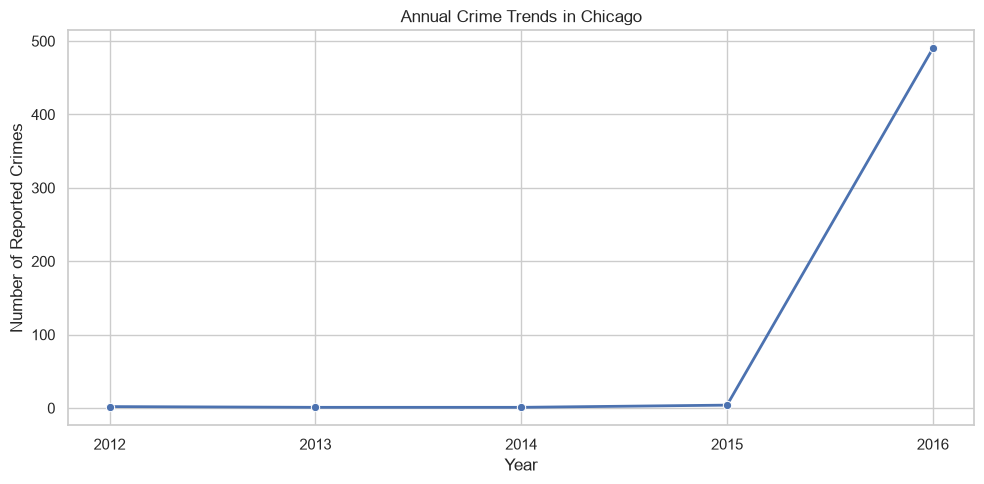

In [7]:
# Group crime records by year
yearly_crimes = (
    analysis_df
    .dropna(subset=["Year"])
    .groupby("Year")["case_number"]
    .count()
    .reset_index(name="Total_Crimes")
)

# Display annual crime counts
display(yearly_crimes)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_crimes,
    x="Year",
    y="Total_Crimes",
    marker="o",
    linewidth=2
)

plt.title("Annual Crime Trends in Chicago")
plt.xlabel("Year")
plt.ylabel("Number of Reported Crimes")
plt.xticks(yearly_crimes["Year"])
plt.grid(True)

plt.tight_layout()
plt.show()

Identify and visualize the top 10 primary crime types and their percentages.

,Primary_Type,Crime_Count,Percentage
0,THEFT,105,21.084337
1,BATTERY,85,17.068273
2,CRIMINAL DAMAGE,49,9.839357
3,OTHER OFFENSE,39,7.831325
4,DECEPTIVE PRACTICE,38,7.630522
5,ASSAULT,35,7.028112
6,NARCOTICS,32,6.425703
7,ROBBERY,30,6.024096
8,CRIMINAL TRESPASS,17,3.413655
9,MOTOR VEHICLE THEFT,16,3.212851


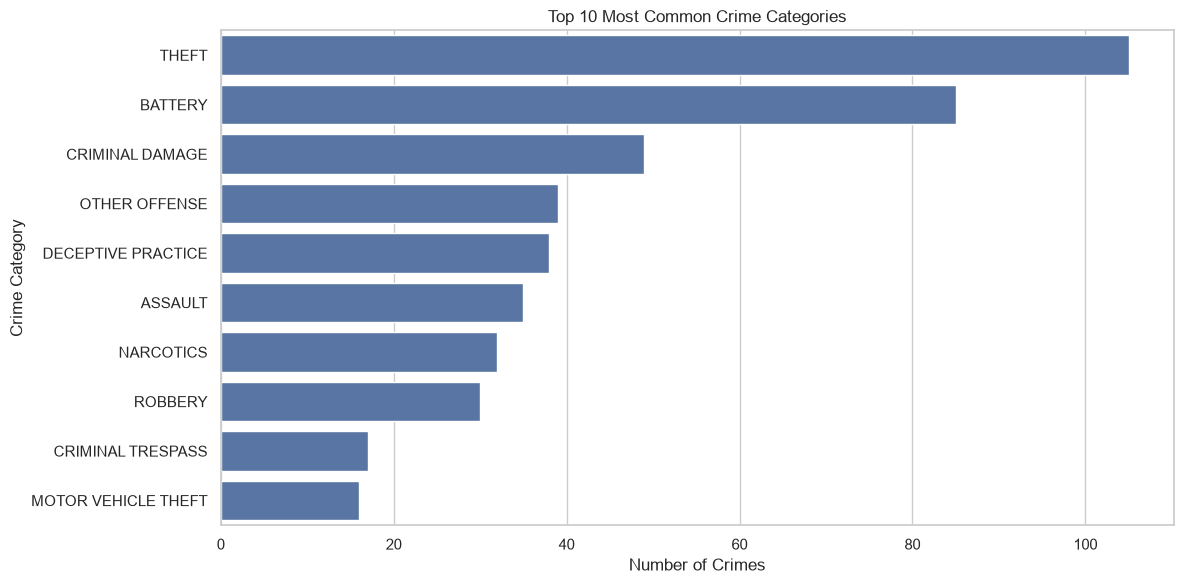

In [8]:
# Count crimes by primary type
crime_type_counts = (
    analysis_df["primary_type"]
    .value_counts()
    .head(10)
)

# Calculate percentages against all records
crime_type_percentages = (
    analysis_df["primary_type"]
    .value_counts(normalize=True)
    .head(10) * 100
)

# Combine counts and percentages
top_10_crimes = pd.DataFrame({
    "Primary_Type": crime_type_counts.index,
    "Crime_Count": crime_type_counts.values,
    "Percentage": crime_type_percentages.values
})

display(top_10_crimes)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_crimes,
    x="Crime_Count",
    y="Primary_Type"
)

plt.title("Top 10 Most Common Crime Categories")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Category")

plt.tight_layout()
plt.show()

Calculate the overall arrest rate

In [9]:
# Count arrested and non-arrested records
arrest_counts = analysis_df["arrest"].value_counts()

print("Arrest counts:")
display(arrest_counts)

# Calculate overall arrest rate
total_records = analysis_df["arrest"].notna().sum()

total_arrests = (
    analysis_df["arrest"] == True
).sum()

arrest_rate = (total_arrests / total_records) * 100

print(f"Total records with arrest information: {total_records}")
print(f"Total arrests: {total_arrests}")
print(f"Overall arrest rate: {arrest_rate:.2f}%")

Arrest counts:


arrest
False    374
True     124
Name: count, dtype: int64

Total records with arrest information: 498
Total arrests: 124
Overall arrest rate: 24.90%


Calculate and visualize arrest rates by year

,Year,Total_Crimes,Total_Arrests,Arrest_Rate
0,2012,2,2,100.000000
1,2013,1,1,100.000000
2,2014,1,0,0.000000
3,2015,4,2,50.000000
4,2016,490,119,24.285714


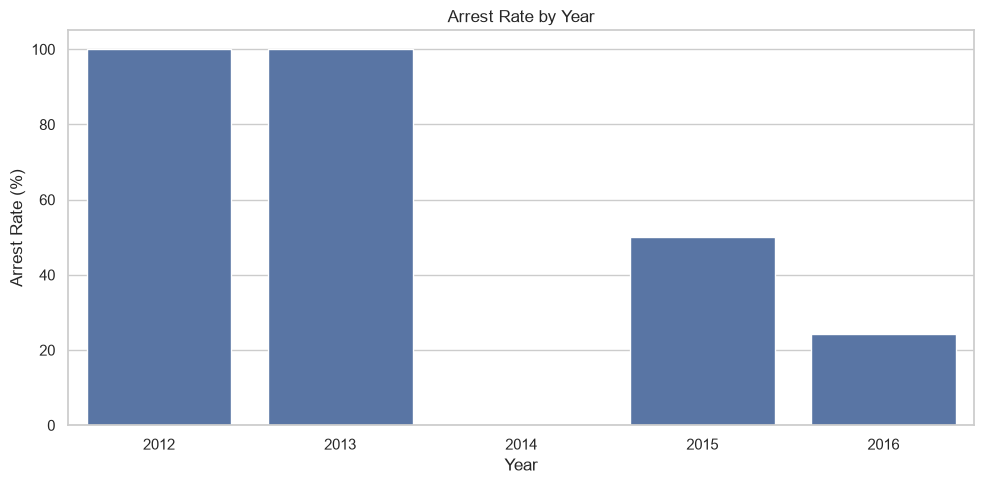

In [11]:
yearly_arrests = (
    analysis_df
    .dropna(subset=["Year", "arrest"])
    .groupby("Year")
    .agg(
        Total_Crimes=("case_number", "count"),
        Total_Arrests=("arrest", "sum")
    )
    .reset_index()
)

yearly_arrests["Arrest_Rate"] = (
    yearly_arrests["Total_Arrests"] /
    yearly_arrests["Total_Crimes"]
) * 100

display(yearly_arrests)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_arrests,
    x="Year",
    y="Arrest_Rate"
)

plt.title("Arrest Rate by Year")
plt.xlabel("Year")
plt.ylabel("Arrest Rate (%)")

plt.tight_layout()
plt.show()

Compare arrested and non-arrested records

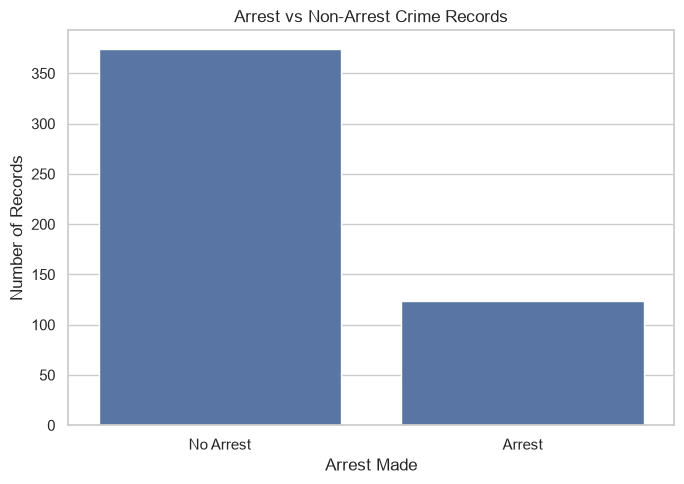

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=analysis_df,
    x="arrest"
)

plt.title("Arrest vs Non-Arrest Crime Records")
plt.xlabel("Arrest Made")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Arrest", "Arrest"])

plt.tight_layout()
plt.show()

Calculate and visualize monthly crime counts

,Month,Total_Crimes
0,1,10
1,2,5
2,3,12
3,4,22
4,5,447
5,11,2


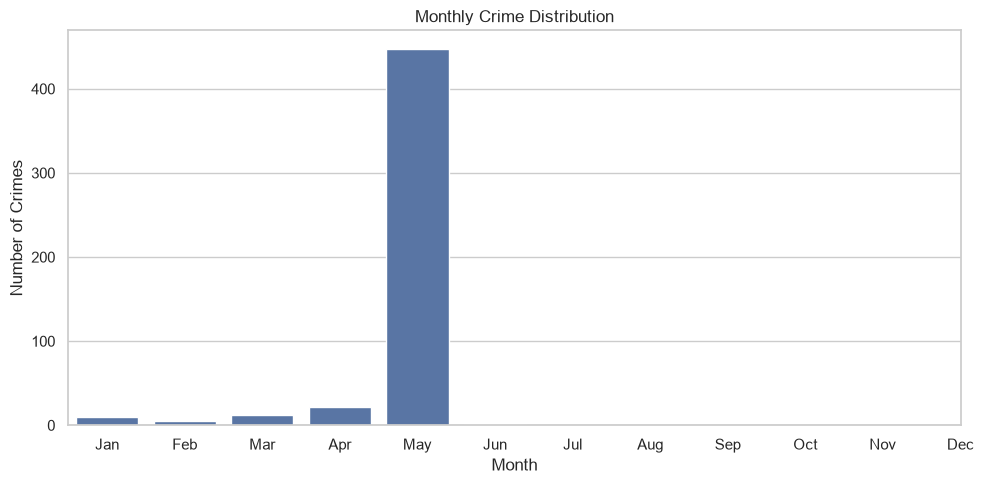

In [14]:
# Count crimes by month
monthly_crimes = (
    analysis_df
    .dropna(subset=["Month"])
    .groupby("Month")["case_number"]
    .count()
    .reset_index(name="Total_Crimes")
)

# Display monthly crime counts
display(monthly_crimes)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_crimes,
    x="Month",
    y="Total_Crimes"
)

plt.title("Monthly Crime Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")

plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

plt.tight_layout()
plt.show()

Identify the peak crime month

In [15]:
peak_month = monthly_crimes.loc[
    monthly_crimes["Total_Crimes"].idxmax()
]

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

print("Peak crime month:", month_names[int(peak_month["Month"])])
print("Number of crimes:", int(peak_month["Total_Crimes"]))

Peak crime month: May
Number of crimes: 447


Create the month versus weekday heatmap

DayOfWeek
Wednesday    303
Tuesday      156
Monday        12
Friday        11
Sunday         6
Thursday       5
Saturday       5
Name: count, dtype: int64


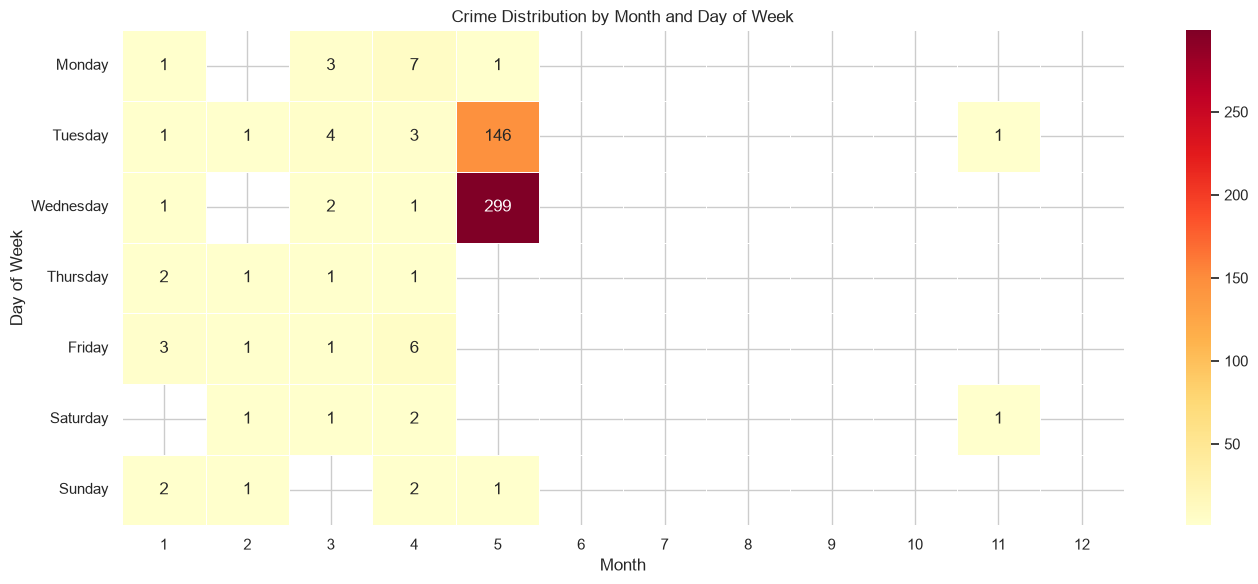

In [16]:
print(analysis_df["DayOfWeek"].value_counts(dropna=False))

# Define weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Create month and weekday crime count table
crime_heatmap_data = analysis_df.pivot_table(
    index="DayOfWeek",
    columns="Month",
    values="case_number",
    aggfunc="count"
)

# Arrange weekdays in calendar order
crime_heatmap_data = crime_heatmap_data.reindex(weekday_order)

# Arrange months in numerical order
crime_heatmap_data = crime_heatmap_data.reindex(
    columns=range(1, 13)
)

# Plot heatmap
plt.figure(figsize=(14, 6))

sns.heatmap(
    crime_heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Crime Distribution by Month and Day of Week")
plt.xlabel("Month")
plt.ylabel("Day of Week")

plt.tight_layout()
plt.show()

Check missing community information

In [17]:
print("Total crime records:", len(analysis_df))

print(
    "Records with missing community names:",
    analysis_df["community_name"].isna().sum()
)

print(
    "Records with available community names:",
    analysis_df["community_name"].notna().sum()
)

Total crime records: 498
Records with missing community names: 0
Records with available community names: 498


Calculate the top 10 community areas

In [20]:
# Keep records with available community information
community_data = analysis_df.dropna(
    subset=["community_code", "community_name"]
).copy()

# Count crimes by community
community_crime_counts = (
    community_data
    .groupby(
        ["community_code", "community_name"]
    )["case_number"]
    .count()
    .reset_index(name="Crime_Count")
    .sort_values("Crime_Count", ascending=False)
)

# Select top 10 community areas
top_10_communities = community_crime_counts.head(10).copy()

known_community_total = len(community_data)

top_10_communities["Percentage"] = (
    top_10_communities["Crime_Count"] /
    known_community_total
) * 100

top_10_communities = top_10_communities[
    ["community_name", "community_code", "Crime_Count", "Percentage"]
].reset_index(drop=True)

display(top_10_communities)

,community_name,community_code,Crime_Count,Percentage
0,Austin,25,34,6.827309
1,Humboldt Park,23,20,4.016064
2,Near North Side,8,20,4.016064
3,South Lawndale,30,16,3.212851
4,South Shore,43,16,3.212851
5,Englewood,68,16,3.212851
6,Loop,32,15,3.012048
7,Auburn Gresham,71,14,2.811245
8,Lake View,6,14,2.811245
9,Roseland,49,14,2.811245


Visualize the top 10 community areas and Identify the community with the highest crime count

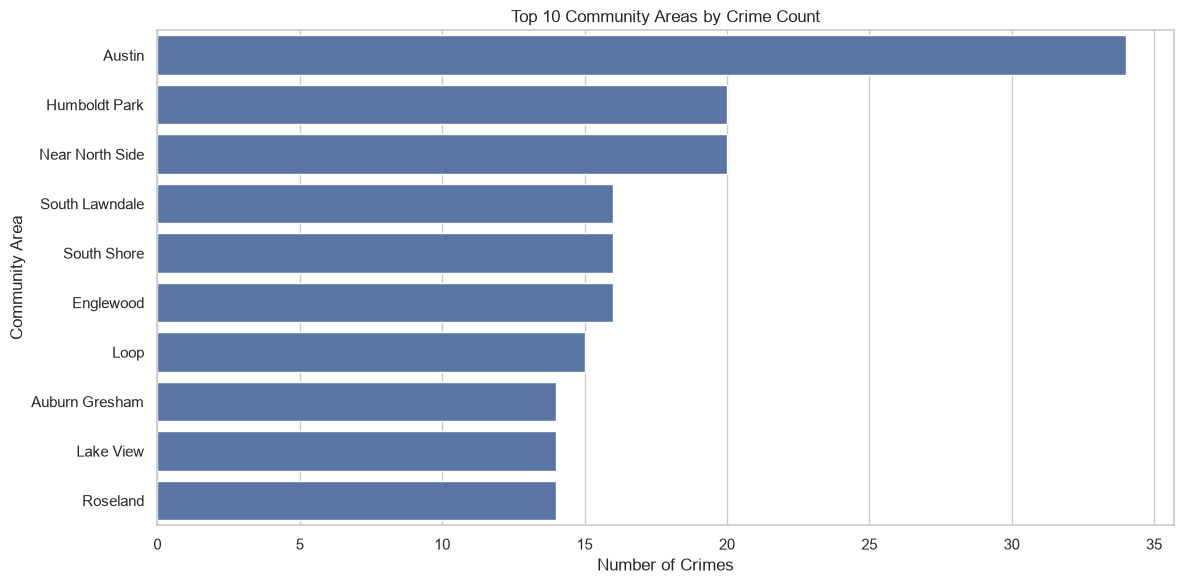

Community area with the highest crime count: Austin
Community code: 25
Number of crime records: 34
Percentage of records with known community: 6.83%


In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_communities,
    x="Crime_Count",
    y="community_name"
)

plt.title("Top 10 Community Areas by Crime Count")
plt.xlabel("Number of Crimes")
plt.ylabel("Community Area")

plt.tight_layout()
plt.show()


highest_crime_community = top_10_communities.iloc[0]

print(
    "Community area with the highest crime count:",
    highest_crime_community["community_name"]
)

print(
    "Community code:",
    highest_crime_community["community_code"]
)

print(
    "Number of crime records:",
    highest_crime_community["Crime_Count"]
)

print(
    "Percentage of records with known community:",
    f"{highest_crime_community['Percentage']:.2f}%"
)


Save the EDA results and Close the database connection

In [26]:
# Create reports directory if it does not exist
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save analysis results
yearly_crimes.to_csv(
    REPORTS_DIR / "yearly_crime_counts.csv",
    index=False
)

top_10_crimes.to_csv(
    REPORTS_DIR / "top_10_crime_categories.csv",
    index=False
)

yearly_arrests.to_csv(
    REPORTS_DIR / "yearly_arrest_rates.csv",
    index=False
)

monthly_crimes.to_csv(
    REPORTS_DIR / "monthly_crime_counts.csv",
    index=False
)

top_10_communities.to_csv(
    REPORTS_DIR / "top_10_community_areas.csv",
    index=False
)

print("EDA result tables saved successfully!")

connection.close()

print("SQLite database connection closed successfully!")

EDA result tables saved successfully!
SQLite database connection closed successfully!
